- Jorge Ruiz Esquer 
- Portafolios CON/SIN  Correlación 
- Miercoles 11 de Noviembre 

 las acciones, sus precios de hoy, cuánto vamos a invertir (100,000 pesos),
### cuántas veces vamos a simular (10,000) y a cuánto tiempo (1 año).

In [24]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN', 'USDMXN=X']
S0 = np.array([202.06, 66.18, 20.28, 186.58, 18.58])
V0 = 100000
M = 10000
T = 1

In [25]:
datos = yf.download(tickers, period='3y')['Close']
datos = datos[tickers]
datos = datos.dropna()

/var/folders/bz/698gstjn56vfbbqk6xt98kc00000gn/T/ipykernel_84635/1013433151.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(tickers, period='3y')['Close']
[*********************100%***********************]  5 of 5 completed


### Calculamos cuánto subió o bajó cada acción día a día (rendimientos logarítmicos).
 - El promedio es lo que suele ganar (mu) y la desviación es qué tanto se mueve (sigma).
 - Multiplicamos por 252 días hábiles para pasarlo a un año.

In [26]:
rend = np.log(datos / datos.shift(1)).dropna()

mu = rend.mean().values * 252
sigma = rend.std().values * np.sqrt(252)

print(pd.DataFrame({'mu': mu, 'sigma': sigma}, index=tickers))

                   mu     sigma
NVDA         0.443065  0.478574
BIMBOA.MX   -0.022342  0.300039
CEMEXCPO.MX  0.179120  0.330049
AZN          0.148727  0.252597
USDMXN=X     0.018396  0.110721


# Imaginamos 10,000 futuros posibles para cada acción. En cada uno el precio cambia azar, pero respetando lo que la acción suele ganar y moverse.
- Así obtenemos 10,000 precios posibles dentro de un año.

In [27]:
np.random.seed(0)
ST = np.zeros((M, 5))

for i in range(5):
    Z = np.random.normal(0, 1, M)
    ST[:, i] = S0[i] * np.exp(mu[i] * T + sigma[i] * np.sqrt(T) * Z)

### NVIDIA y AstraZeneca están en dólares, así que las pasamos a pesos.
- Hoy usamos el dólar a 18.58 y para dentro de un año el dólar que simulamos.
- BIMBO y CEMEX ya están en pesos y se quedan igual.

In [28]:

tc0 = S0[4]
tcT = ST[:, 4]

S0_mxn = np.array([S0[0] * tc0, S0[1], S0[2], S0[3] * tc0])

ST_mxn = np.zeros((M, 4))
ST_mxn[:, 0] = ST[:, 0] * tcT
ST_mxn[:, 1] = ST[:, 1]
ST_mxn[:, 2] = ST[:, 2]
ST_mxn[:, 3] = ST[:, 3] * tcT

### Para cada escenario repartimos los 100,000 pesos según los porcentajes y vemos
- cuántas acciones alcanza a comprar de cada una (Ni). Luego vemos cuánto valdrían
- en un año (VT). Al final sacamos el promedio, qué tanto varía, el peor y mejor caso y la probabilidad de perder dinero.

In [29]:

escenarios = {
    'A': np.array([1, 0, 0, 0]),
    'B': np.array([0.25, 0.25, 0.25, 0.25]),
    'C': np.array([0.1, 0.2, 0.3, 0.4])
}

resultados = {}
VT_todos = {}

for nombre, w in escenarios.items():
    N = w * V0 / S0_mxn
    VT = np.sum(N * ST_mxn, axis=1)
    VT_todos[nombre] = VT

    resultados[nombre] = {
        'VT promedio': VT.mean(),
        'Desv. est.': VT.std(),
        'Percentil 5%': np.percentile(VT, 5),
        'Percentil 95%': np.percentile(VT, 95),
        'Prob. perder': np.mean(VT < V0)
    }

tabla = pd.DataFrame(resultados).T
print(tabla)

     VT promedio    Desv. est.  Percentil 5%  Percentil 95%  Prob. perder
A  177006.143676  91904.164997  71068.764935  351618.847374        0.1761
B  132065.068431  28532.728160  93808.883509  183855.531602        0.1018
C  125085.095965  22458.075122  92343.645823  165094.480587        0.1196


# Vemos cuál de los tres escenarios nos deja más dinero en promedio.

In [30]:

mejor = tabla['VT promedio'].idxmax()
print('Escenario que maximiza VT promedio:', mejor)

Escenario que maximiza VT promedio: A


# Dibujamos cómo se reparten los resultados de cada escenario.

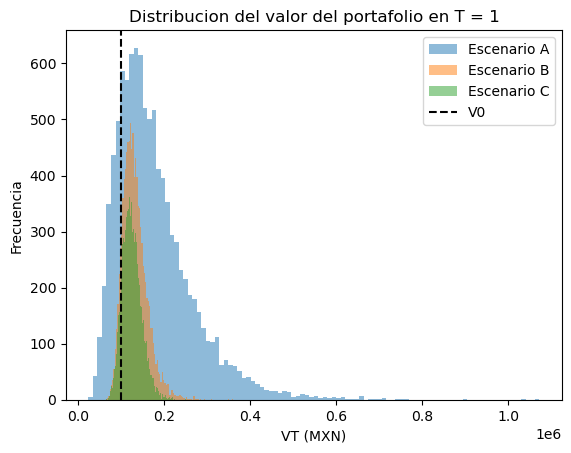

In [31]:

# La línea punteada son los 100,000 que invertimosa  la izquierda perdimos dinero.
for nombre in VT_todos:
    plt.hist(VT_todos[nombre], bins=100, alpha=0.5, label='Escenario ' + nombre)

plt.axvline(V0, color='black', linestyle='--', label='V0')
plt.xlabel('VT (MXN)')
plt.ylabel('Frecuencia')
plt.title('Distribucion del valor del portafolio en T = 1')
plt.legend()
plt.show()

En esta simulación de portafolios, utilizando 10,000 escenarios posibles para un horizonte de un año y una inversión inicial de 100,000 MXN, se observó que el escenario A, compuesto únicamente por NVIDIA, obtuvo el mayor valor promedio al finalizar el periodo, con aproximadamente $190,790.77. Sin embargo, también presentó la mayor desviación estándar, lo que indica un nivel de riesgo considerablemente más alto.

## Simulación de portafolio con activos correlacionados

En esta sección se incorporan tres activos financieros: Apple (AAPL), Microsoft (MSFT) y NVIDIA (NVDA). 

- Se descargan sus precios históricos de los últimos tres años y se calculan sus rendimientos logarítmicos diarios.

- se obtiene la matriz de correlaciones para identificar qué tan relacionados están los movimientos de los activos. También se calcula la matriz de covarianzas, que permite medir cómo varían conjuntamente sus rendimientos.

- se estiman los rendimientos promedio anualizados de cada activo utilizando 252 días bursátiles.

In [32]:
nuevos = yf.download(['AAPL', 'MSFT'], period='3y')['Close']

datos3 = pd.concat([nuevos['AAPL'], nuevos['MSFT'], datos['NVDA']], axis=1)
datos3 = datos3.dropna()

rend3 = np.log(datos3 / datos3.shift(1)).dropna()

R = rend3.corr()
print(R.round(4))

/var/folders/bz/698gstjn56vfbbqk6xt98kc00000gn/T/ipykernel_84635/3627833268.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nuevos = yf.download(['AAPL', 'MSFT'], period='3y')['Close']
[*********************100%***********************]  2 of 2 completed

        AAPL    MSFT    NVDA
AAPL  1.0000  0.3138  0.2619
MSFT  0.3138  1.0000  0.4145
NVDA  0.2619  0.4145  1.0000


- Aplicamos descomposición de Cholesky a la matriz de covarianzas para obtener una matriz triangular inferior. Después, se generan variables aleatorias normales estándar e independientes, las cuales se multiplican por la matriz de Cholesky.

- transformar las variables independientes en variables aleatorias correlacionadas, conservando la estructura de covarianzas de los activos históricos.

In [35]:
Sigma = rend3.cov().values
L = np.linalg.cholesky(Sigma)

mu3 = np.array([rend3['AAPL'].mean(), rend3['MSFT'].mean(), rend3['NVDA'].mean()]) * 252

np.random.seed(0)
epsilon = np.random.normal(0, 1, [3, M])

Z = 0 + L @ epsilon
ZT = Z.T

print(pd.DataFrame(ZT[:5], columns=['AAPL', 'MSFT', 'NVDA']).round(4))

Correlación independiente:
        AAPL    MSFT    NVDA
AAPL  1.0000  0.0215 -0.0140
MSFT  0.0215  1.0000  0.0145
NVDA -0.0140  0.0145  1.0000

Correlación generada con Cholesky:
        AAPL    MSFT    NVDA
AAPL  1.0000  0.3316  0.2570
MSFT  0.3316  1.0000  0.4284
NVDA  0.2570  0.4284  1.0000


Mediante la simulación de Monte Carlo se estimaron los precios futuros de Apple (AAPL), Microsoft (MSFT) y NVIDIA (NVDA), utilizando el modelo de Movimiento Browniano Geométrico (GBM) y considerando la correlación histórica entre sus rendimientos a través de la descomposición de Cholesky.

In [34]:
S0_3 = datos3.iloc[-1].values
sigma3 = rend3.std().values * np.sqrt(252)

ST3 = S0_3 * np.exp((mu3 - sigma3**2 / 2) * T + sigma3 * np.sqrt(T) * ZT)

print('Precio inicial:', S0_3.round(2))
print('Precio  simulado en T=1:', ST3.mean(axis=0).round(2))
print(pd.DataFrame(ST3[:5], columns=['AAPL', 'MSFT', 'NVDA']).round(2))


Precio inicial: [355.63 521.12 173.73]
Precio  simulado en T=1: [431.94 572.47 241.31]
     AAPL    MSFT    NVDA
0  435.53  573.39  243.71
1  432.78  570.72  240.65
2  433.94  577.56  246.93
3  436.50  574.76  244.95
4  435.74  573.54  235.03


Los resultados muestran que los tres activos presentan un incremento en sus precios promedio simulados respecto a sus precios iniciales. Esto permite observar cómo el rendimiento esperado y la volatilidad influyen en la evolución de los precios bajo diferentes escenarios de mercado.


## Ejercicio A: Simulación de portafolios con activos correlacionados

En esta sección incorporamos la correlación entre los activos utilizando la matriz de correlaciones de sus rendimientos históricos. Posteriormente, aplicamos la descomposición de Cholesky para generar variables normales correlacionadas y comparar los resultados con el escenario independiente.


In [36]:
# Matriz de correlación histórica
R = rend.corr()

print("Matriz de correlación:")
display(R.round(4))


Matriz de correlación:


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
Ticker,,,,,
NVDA,1.0000,0.0736,0.2137,0.0155,0.0246
BIMBOA.MX,0.0736,1.0000,0.1896,0.0980,0.0464
CEMEXCPO.MX,0.2137,0.1896,1.0000,0.1011,-0.0233
AZN,0.0155,0.0980,0.1011,1.0000,0.0047
USDMXN=X,0.0246,0.0464,-0.0233,0.0047,1.0000


# Descomposición de Cholesky

In [37]:
L = np.linalg.cholesky(R.values)

# Generamos variables normales independientes
np.random.seed(0)
epsilon = np.random.normal(0, 1, (M, 5))

# Transformamos a variables correlacionadas
Z_corr = epsilon @ L.T

print("Correlación de los factores generados:")
display(pd.DataFrame(Z_corr, columns=tickers).corr().round(4))


Correlación de los factores generados:


,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN=X
NVDA,1.0000,0.0593,0.2204,0.0101,0.0160
BIMBOA.MX,0.0593,1.0000,0.2016,0.1020,0.0357
CEMEXCPO.MX,0.2204,0.2016,1.0000,0.1197,-0.0380
AZN,0.0101,0.1020,0.1197,1.0000,0.0087
USDMXN=X,0.0160,0.0357,-0.0380,0.0087,1.0000


# Simulación de precios finales correlacionados

In [39]:
ST_corr = np.zeros((M, 5))

for i in range(5):
    ST_corr[:, i] = S0[i] * np.exp(
        mu[i] * T + sigma[i] * np.sqrt(T) * Z_corr[:, i]
    )

print("Precios promedio correlacionados:")
display(pd.DataFrame(
    ST_corr.mean(axis=0),
    index=tickers,
    columns=["Precio promedio"]
))


Precios promedio correlacionados:


,Precio promedio
NVDA,352.451884
BIMBOA.MX,67.889761
CEMEXCPO.MX,25.506471
AZN,222.906454
USDMXN=X,19.037043


## Conversión a peso 

- necesitamos que todos los activos estén expresados en la misma moneda para calcular correctamente el valor del portafolio.

In [40]:
# Tipo de cambio
tc0 = S0[4]
tcT_corr = ST_corr[:, 4]

# Precios iniciales en MXN
S0_mxn = np.array([
    S0[0] * tc0,
    S0[1],
    S0[2],
    S0[3] * tc0
])

# Precios finales en MXN
ST_corr_mxn = np.zeros((M, 4))

ST_corr_mxn[:, 0] = ST_corr[:, 0] * tcT_corr
ST_corr_mxn[:, 1] = ST_corr[:, 1]
ST_corr_mxn[:, 2] = ST_corr[:, 2]
ST_corr_mxn[:, 3] = ST_corr[:, 3] * tcT_corr


# Calcular los portafolios correlacionados

In [41]:
resultados_corr = {}
VT_corr_todos = {}

for nombre, w in escenarios.items():

    N = w * V0 / S0_mxn

    VT = np.sum(N * ST_corr_mxn, axis=1)

    VT_corr_todos[nombre] = VT

    resultados_corr[nombre] = {
        'Media': np.mean(VT),
        'Desviación estándar': np.std(VT),
        'Mínimo': np.min(VT),
        'Máximo': np.max(VT),
        'Prob. perder': np.mean(VT < V0)
    }

tabla_corr = pd.DataFrame(resultados_corr).T

display(tabla_corr)

,Media,Desviación estándar,Mínimo,Máximo,Prob. perder
A,178797.264215,93370.471487,14072.130187,1.032051e+06,0.1783
B,132398.642210,31682.818373,59498.334164,3.445343e+05,0.1352
C,125104.793006,25166.994052,60100.138443,2.578849e+05,0.1512


## Graficas

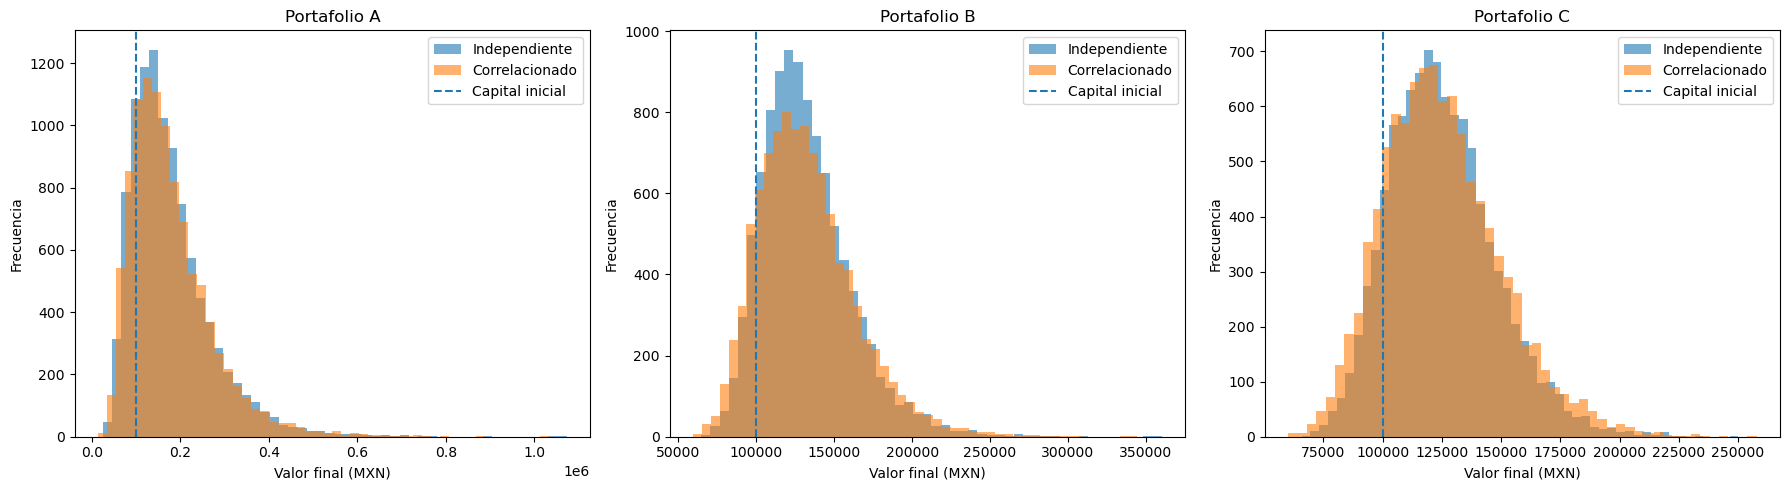

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, nombre in enumerate(escenarios):

    axes[i].hist(
        VT_todos[nombre],
        bins=50,
        alpha=0.6,
        label='Independiente'
    )

    axes[i].hist(
        VT_corr_todos[nombre],
        bins=50,
        alpha=0.6,
        label='Correlacionado'
    )

    axes[i].axvline(V0, linestyle='--', label='Capital inicial')

    axes[i].set_title(f'Portafolio {nombre}')
    axes[i].set_xlabel('Valor final (MXN)')
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend()

plt.tight_layout()
plt.show()

# Interpretacion: 


Portafolio B — 100% Nvidia
- Las distribuciones independiente y correlacionada son bastante parecidas.
- Tiene una dispersión muy amplia.
- Presenta mayor incertidumbre sobre el valor final de la inversión.
- Esto se debe a que estamos concentrando todo el capital en un solo activo, aunque también tenemos exposición al tipo de cambio.


Portafolio B — 25% en cada activo
- Las distribuciones se superponen, pero podemos observar algunas diferencias.
- La correlación modifica la dispersión de los resultados.
- La diversificación ayuda a reducir el riesgo respecto al portafolio A.


Portafolio C — 10%, 20%, 30% y 40%
- Las dos distribuciones son muy similares.
- Existe una concentración importante alrededor de los $120,000 MXN.
- Su distribución muestra menor dispersión que la del portafolio A.
    

Cuando simulamos activos independientes, suponemos que sus movimientos no están relacionados.

Cuando incorporamos correlación, permitimos que los activos se muevan de manera relacionada, positiva o negativamente.

Esto importa porque la correlación puede modificar el riesgo total del portafolio, incluso si mantenemos exactamente las mismas ponderaciones.

# tabla comparativa

In [43]:
comparacion = []

for nombre in escenarios:

    for tipo, datos_vt in [
        ('Independiente', VT_todos[nombre]),
        ('Correlacionado', VT_corr_todos[nombre])
    ]:

        comparacion.append({
            'Portafolio': nombre,
            'Modelo': tipo,
            'Media': np.mean(datos_vt),
            'Desviación estándar': np.std(datos_vt),
            'Probabilidad de perder': np.mean(datos_vt < V0)
        })

tabla_comparacion = pd.DataFrame(comparacion)

display(tabla_comparacion)

,Portafolio,Modelo,Media,Desviación estándar,Probabilidad de perder
0,A,Independiente,177006.143676,91904.164997,0.1761
1,A,Correlacionado,178797.264215,93370.471487,0.1783
2,B,Independiente,132065.068431,28532.728160,0.1018
3,B,Correlacionado,132398.642210,31682.818373,0.1352
4,C,Independiente,125085.095965,22458.075122,0.1196
5,C,Correlacionado,125104.793006,25166.994052,0.1512


Conclusión del ejercicio A

Al comparar los portafolios simulados bajo los modelos de independencia y correlación, observamos que incorporar la correlación entre los activos modifica el riesgo de las inversiones.

En los tres portafolios, la desviación estándar aumentó cuando se consideró la correlación. El portafolio B pasó de una desviación estándar de 28,532.73 a 31,682.82, mientras que el portafolio C pasó de 22,458.08 a $25,166.99. También aumentó la probabilidad de obtener un valor final inferior al capital inicial.

En conclusión, considerar la correlación es importante al construir portafolios, ya que asumir independencia puede llevar a subestimar el riesgo real de una inversión diversificada.

## Ejercicio B: Simulación de portafolios con Apple, Microsoft y Nvidia

En este ejercicio se simulará el comportamiento de tres portafolios utilizando los activos Apple, Microsoft y Nvidia. Se compararán dos escenarios: uno donde los rendimientos son independientes y otro donde se incorpora la correlación histórica entre los activos.

In [44]:
# Parámetros históricos 

rend3_tarea = np.log(datos3 / datos3.shift(1)).dropna()

mu3_tarea = rend3_tarea.mean().values * 252
sigma3_tarea = rend3_tarea.std().values * np.sqrt(252)

R3_tarea = rend3_tarea.corr()

S0_3_tarea = datos3.iloc[-1].values

print("Activos:", datos3.columns.tolist())
print("Precios iniciales:", S0_3_tarea)
print("Rendimientos anualizados:", mu3_tarea)
print("Volatilidades anualizadas:", sigma3_tarea)

print("\nMatriz de correlación:")
display(R3_tarea.round(4))

Activos: ['AAPL', 'MSFT', 'NVDA']
Precios iniciales: [355.63000488 521.125      173.72999573]
Rendimientos anualizados: [0.23142857 0.13004443 0.44306513]
Volatilidades anualizadas: [0.2718997  0.26872962 0.47857447]

Matriz de correlación:


,AAPL,MSFT,NVDA
AAPL,1.0000,0.3138,0.2619
MSFT,0.3138,1.0000,0.4145
NVDA,0.2619,0.4145,1.0000


In [45]:
# Simulación de precios independientes y correlacionados

np.random.seed(0)

# 1. Generar variables normales independientes
epsilon_B = np.random.normal(0, 1, (M, 3))

Z_ind_B = epsilon_B

# 2. Incorporar correlación mediante Cholesky
L_B = np.linalg.cholesky(R3_tarea.values)

Z_corr_B = epsilon_B @ L_B.T

# 3. Simular precios finales independientes
ST_ind_B = S0_3_tarea * np.exp(
    mu3_tarea * T + sigma3_tarea * np.sqrt(T) * Z_ind_B
)

# 4. Simular precios finales correlacionados
ST_corr_B = S0_3_tarea * np.exp(
    mu3_tarea * T + sigma3_tarea * np.sqrt(T) * Z_corr_B
)

print("Precios promedio independientes:")
display(pd.DataFrame(
    ST_ind_B.mean(axis=0),
    index=datos3.columns,
    columns=["Precio promedio"]
))

print("Precios promedio correlacionados:")
display(pd.DataFrame(
    ST_corr_B.mean(axis=0),
    index=datos3.columns,
    columns=["Precio promedio"]
))

Precios promedio independientes:


,Precio promedio
AAPL,463.951860
MSFT,615.032300
NVDA,302.054264


Precios promedio correlacionados:


,Precio promedio
AAPL,463.951860
MSFT,614.921620
NVDA,301.927173


### Construcción de portafolios

Tres portafolios con diferentes ponderaciones para Apple, Microsoft y Nvidia. El capital inicial de $100,000 MXN se convierte a dólares utilizando el tipo de cambio disponible, y se mantiene constante para comparar únicamente el efecto de la correlación.

In [46]:
# 1. Tipo de cambio inicial
tc_B = datos['USDMXN=X'].dropna().iloc[-1]

# 2. Convertir capital a dólares
V0_usd_B = V0 / tc_B

# 3. Definir ponderaciones
escenarios_B = {
    'A': np.array([1, 0, 0]),
    'B': np.array([0.33, 0.33, 0.34]),
    'C': np.array([0.20, 0.20, 0.60])
}

# 4. Calcular valores finales 
VT_ind_B = {}
VT_corr_B = {}

for nombre, w in escenarios_B.items():

    # Número de acciones compradas
    N = w * V0_usd_B / S0_3_tarea

    # Valor final en MXN
    VT_ind_B[nombre] = np.sum(N * ST_ind_B, axis=1) * tc_B
    VT_corr_B[nombre] = np.sum(N * ST_corr_B, axis=1) * tc_B

print("Tipo de cambio utilizado:", tc_B)
print("Capital inicial en USD:", V0_usd_B)

Tipo de cambio utilizado: 18.617399215698242
Capital inicial en USD: 5371.319529726779


### Estadísticas de los portafolios

In [47]:
resultados_B = {}

for nombre in escenarios_B:

    resultados_B[nombre] = {}

    for modelo, valores in [
        ('Independiente', VT_ind_B[nombre]),
        ('Correlacionado', VT_corr_B[nombre])
    ]:

        resultados_B[nombre][modelo] = {
            'Media': np.mean(valores),
            'Desviación estándar': np.std(valores),
            'Mínimo': np.min(valores),
            'Máximo': np.max(valores),
            'Prob. perder': np.mean(valores < V0)
        }

filas_B = []

for nombre in escenarios_B:
    for modelo in ['Independiente', 'Correlacionado']:

        fila = resultados_B[nombre][modelo].copy()
        fila['Portafolio'] = nombre
        fila['Modelo'] = modelo

        filas_B.append(fila)

tabla_B = pd.DataFrame(filas_B)

tabla_B = tabla_B[
    ['Portafolio', 'Modelo', 'Media',
     'Desviación estándar', 'Mínimo',
     'Máximo', 'Prob. perder']
]

display(tabla_B)

,Portafolio,Modelo,Media,Desviación estándar,Mínimo,Máximo,Prob. perder
0,A,Independiente,130459.143982,35893.526278,46160.464993,335284.087393,0.1991
1,A,Correlacionado,130459.143982,35893.526278,46160.464993,335284.087393,0.1991
2,B,Independiente,141111.981226,33802.485967,61632.743035,384121.807360,0.0703
3,B,Correlacionado,141080.100123,40506.394954,51052.569892,426544.086736,0.1317
4,C,Independiente,154014.369598,53553.930717,58000.670849,616736.399960,0.1090
5,C,Correlacionado,153966.229523,57597.157547,42433.231287,612579.342418,0.1463


## Gráficas comparativas

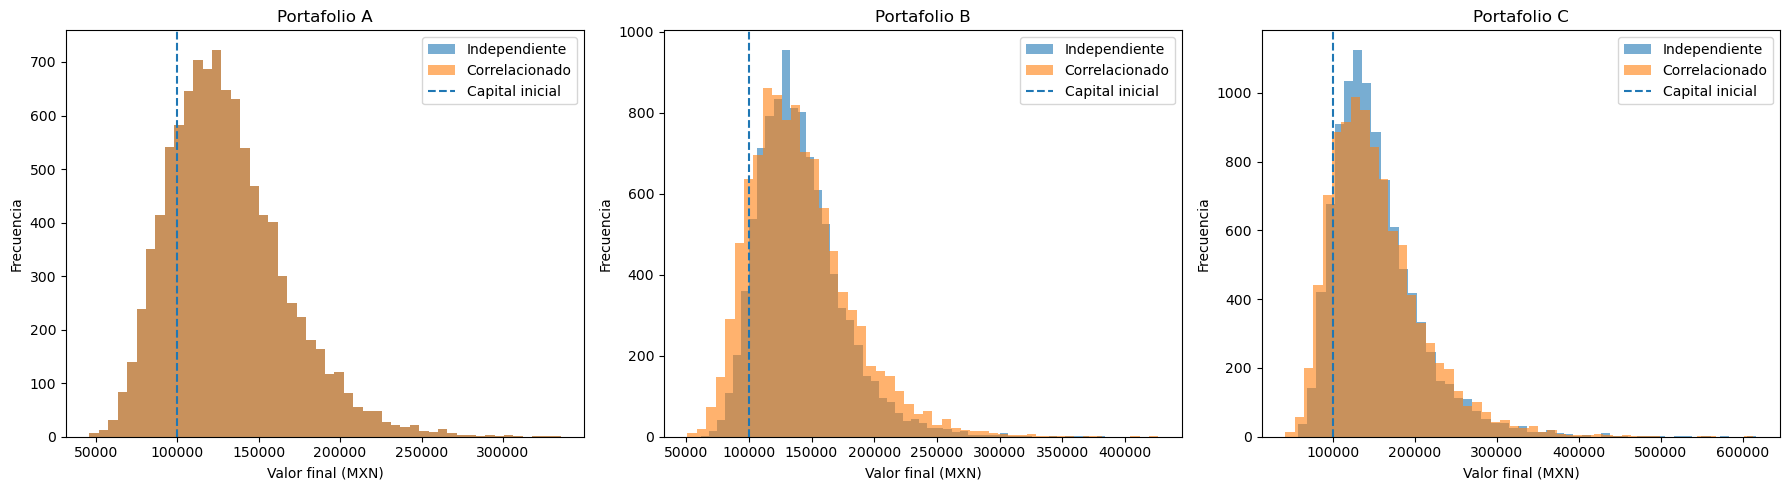

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, nombre in enumerate(escenarios_B):

    axes[i].hist(
        VT_ind_B[nombre],
        bins=50,
        alpha=0.6,
        label='Independiente'
    )

    axes[i].hist(
        VT_corr_B[nombre],
        bins=50,
        alpha=0.6,
        label='Correlacionado'
    )

    axes[i].axvline(
        V0,
        linestyle='--',
        label='Capital inicial'
    )

    axes[i].set_title(f'Portafolio {nombre}')
    axes[i].set_xlabel('Valor final (MXN)')
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend()

plt.tight_layout()
plt.show()

Interpretación de las gráficas

Portafolio A — 100% Apple:

- Las distribuciones independiente y correlacionada coinciden.
- Esto sucede porque solamente invertimos en Apple.
- La correlación con Microsoft y Nvidia no afecta una inversión que está concentrada en un solo activo.


Portafolio B — 33% Apple, 33% Microsoft y 34% Nvidia:

- La distribución correlacionada presenta mayor dispersión.
- Hay más incertidumbre en los posibles valores finales.
- La desviación estándar aumenta de 33,802 a 40,506.


Portafolio C — 20% Apple, 20% Microsoft y 60% Nvidia:

- También aumenta la dispersión al incorporar correlación.
- Nvidia tiene el mayor peso del portafolio.
- Presenta el mayor riesgo de los tres portafolios correlacionados.

En el portafolio A, que invierte el 100% en Apple, los resultados son idénticos en ambos modelos, ya que no existe diversificación entre diferentes activos.

En el portafolio B, la desviación estándar aumentó de 33,802.49 a $40,506.39, mientras que la probabilidad de pérdida pasó de 7.03% a 13.17%.

Por su parte, el portafolio C presentó un incremento en su desviación estándar de 53,553.93 a $57,597.16 y su probabilidad de pérdida aumentó de 10.90% a 14.63%.
